# Predictive modeling

All models run through the shared pipeline (src/pipeline.py) with the params from configs/config.yaml, same as main.py.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from omegaconf import OmegaConf
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score

%load_ext autoreload
%autoreload 2

from src.pipeline import MODELS, build_pipeline

train = pd.read_csv("../data/train.csv")
X, y = train.drop(columns=["Survived"]), train["Survived"]

cfg = OmegaConf.load("../configs/config.yaml")
cv = StratifiedKFold(n_splits=cfg.cv.n_folds, shuffle=True, random_state=cfg.seed)


def pipeline_for(model):
    c = cfg.copy()
    c.model = model
    return build_pipeline(c)

## Cross validation

,mean,std
catboost,0.8361,0.0131
random_forest,0.8328,0.0175
ridge,0.8283,0.0151
logreg,0.8260,0.0108
elasticnet_logreg,0.8238,0.0112
lightgbm,0.8227,0.0116
lasso_logreg,0.8215,0.0136
knn,0.8205,0.0238
xgboost,0.8204,0.0158
decision_tree,0.8081,0.0121


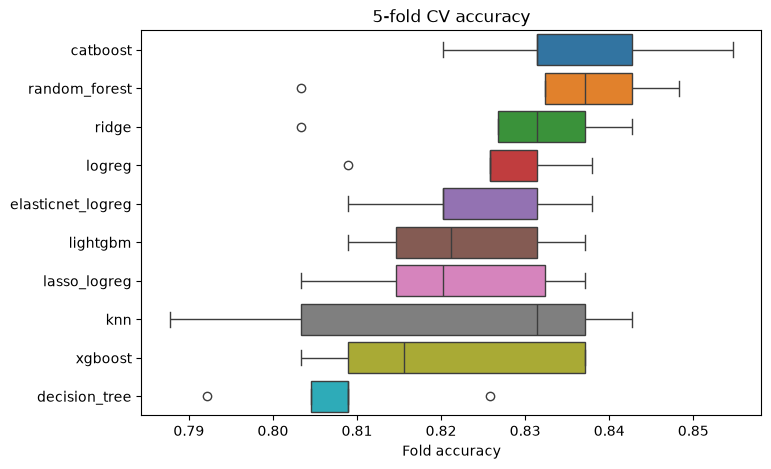

In [2]:
fold_scores = pd.DataFrame(
    {name: cross_val_score(pipeline_for(name), X, y, cv=cv, scoring="accuracy") for name in MODELS}
)

display(fold_scores.agg(["mean", "std"]).T.sort_values("mean", ascending=False).style.format("{:.4f}"))

order = fold_scores.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=fold_scores[order], orient="h", ax=ax)
ax.set_title("5-fold CV accuracy")
ax.set_xlabel("Fold accuracy")
plt.show()

**Observations:**

## Confusion matrices

Out-of-fold predictions: every passenger is predicted by a model that never saw them.

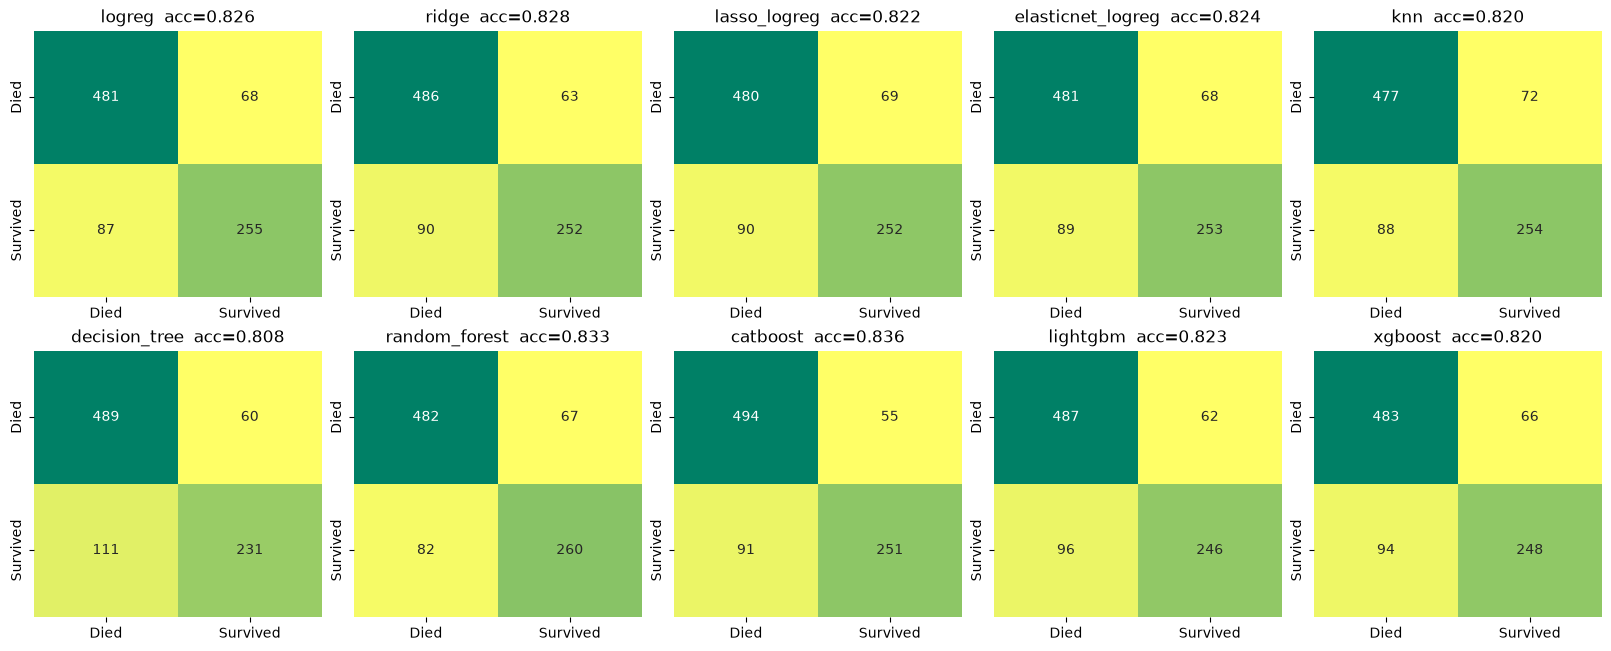

In [3]:
from sklearn.metrics import confusion_matrix

oof_pred = {name: cross_val_predict(pipeline_for(name), X, y, cv=cv) for name in MODELS}

cols = 5
rows = -(-len(MODELS) // cols)
f, axes = plt.subplots(rows, cols, figsize=(16, 3.2 * rows), layout="constrained")
for ax, (name, pred) in zip(axes.flat, oof_pred.items()):
    sns.heatmap(confusion_matrix(y, pred), annot=True, fmt="d", cmap="summer_r", cbar=False,
                xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"], ax=ax)
    ax.set_title(f"{name}  acc={(pred == y).mean():.3f}")
for ax in axes.flat[len(MODELS):]:
    ax.axis("off")
plt.show()

**Observations:**

## Where the errors are

In [4]:
best = fold_scores.mean().idxmax()
errors = train.assign(error=oof_pred[best] != y)

display(
    pd.crosstab(errors["Sex"], errors["Pclass"], values=errors["error"], aggfunc="mean")
    .style.format("{:.0%}").background_gradient(cmap="summer_r", axis=None)
)

all_wrong = pd.DataFrame(oof_pred).ne(y, axis=0).all(axis=1)
print("misclassified by all models:", all_wrong.sum(), "passengers")

Pclass,1,2,3
Sex,,,
female,3%,8%,32%
male,38%,7%,11%


misclassified by all models: 87 passengers


**Observations:**

## Feature importance

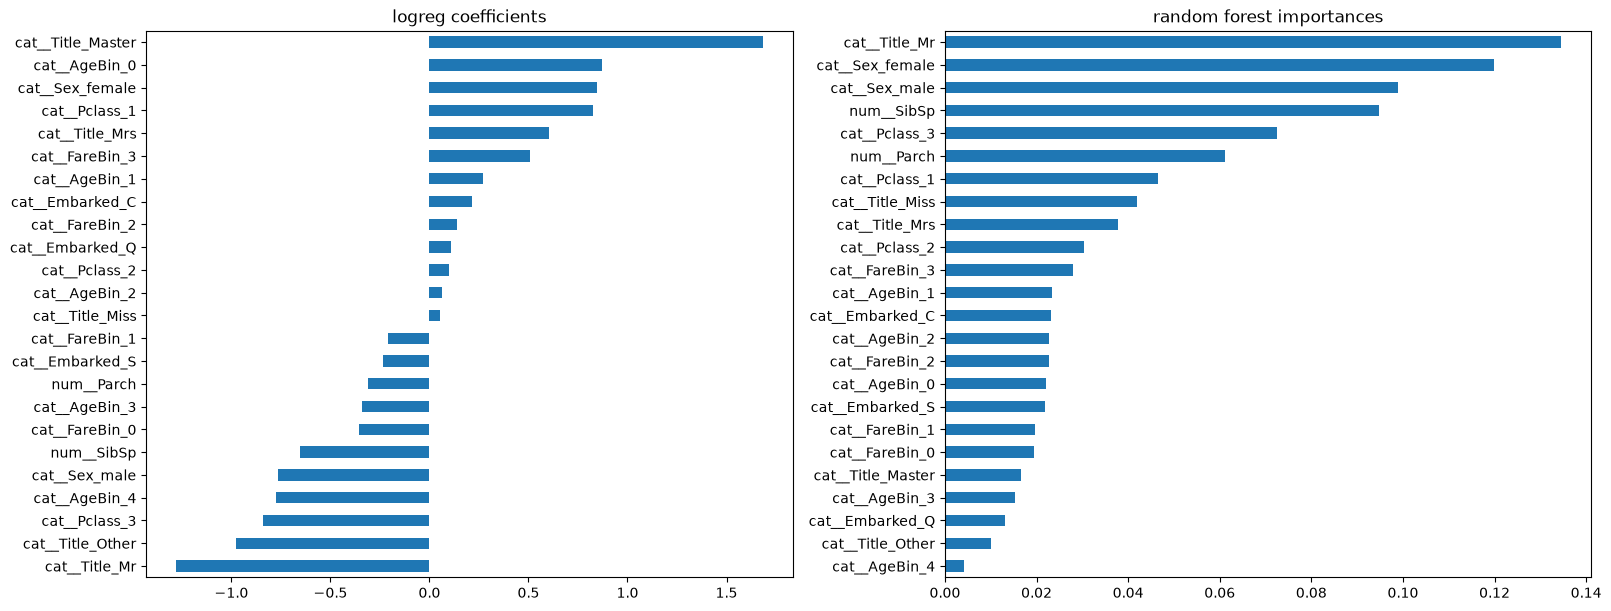

In [5]:
logreg = pipeline_for("logreg").fit(X, y)
forest = pipeline_for("random_forest").fit(X, y)

coefs = pd.Series(
    logreg["model"].coef_[0], index=logreg["preprocess"].get_feature_names_out()
).sort_values()
importances = pd.Series(
    forest["model"].feature_importances_, index=forest["preprocess"].get_feature_names_out()
).sort_values()

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), layout="constrained")
coefs.plot.barh(ax=ax1)
ax1.set_title("logreg coefficients")
importances.plot.barh(ax=ax2)
ax2.set_title("random forest importances")
plt.show()

**Observations:**